# Détection d'URLs de phishing — démonstration scikit-learn

**Cours « Introduction à l'intelligence artificielle » — M2 Cybersécurité**

Ce notebook est la démonstration de code du cours. Il construit, **pas à pas et
ligne par ligne**, un petit système qui *apprend* à distinguer une URL **bénigne**
(légitime) d'une URL de **phishing** (hameçonnage).

> **Pour qui ?** Vous savez coder en Python (variables, boucles, fonctions,
> dictionnaires), mais vous n'avez **jamais fait d'apprentissage automatique**
> (*machine learning*). Chaque terme du domaine est donc défini ici, en français,
> avec une analogie. **Aucun prérequis en IA n'est supposé.**

> **Données 100 % simulées.** Toutes les URLs de ce notebook sont **fabriquées
> localement**, avec une graine aléatoire fixée. Elles n'ont **aucun lien avec des
> URLs réelles** : rien n'est collecté, rien n'est téléchargé, tout fonctionne
> **hors ligne**. C'est un exercice pédagogique, pas un outil de production.

**Comment lire ce notebook :** les cellules de **texte** (comme celle-ci)
expliquent ; les cellules de **code** s'exécutent **dans l'ordre**, de haut en bas
(menu *Run All* / *Tout exécuter*). Chaque cellule de code est commentée ligne par
ligne.

**Le fil rouge :**

1. Le problème, et les mots *classification* / *régression*.
2. Le vocabulaire minimum, dont la **graine aléatoire** (`random_state`).
3. Fabriquer des données simulées.
4. Transformer une URL en **caractéristiques** (des nombres).
5. Couper en **entraînement** / **test**.
6. Entraîner deux modèles : **régression logistique** et **forêt aléatoire**.
7. Mesurer : **matrice de confusion**, **précision**, **rappel**, **F1**.
8. Le **seuil** de décision, et le compromis sécurité / confort.
9. Quelles caractéristiques comptent, et **pourquoi le modèle est fragile**.

## 0. Récupérer le code et lancer le notebook

### a) Cloner le dépôt

« **Cloner** » = télécharger une copie complète du dépôt GitHub sur votre machine.
Ouvrez un terminal (sous Windows : *PowerShell* ou *Git Bash*) et tapez :

```bash
git clone https://github.com/VladdKid/introduction-ia-cybersecurite.git
cd introduction-ia-cybersecurite
```

- `git clone <url>` crée un dossier `introduction-ia-cybersecurite/` contenant tout
  le code et l'historique.
- `cd ...` (« *change directory* ») vous place **dans** ce dossier.
- Pas de `git` ? Installez-le depuis <https://git-scm.com>, ou téléchargez le ZIP
  via le bouton vert **Code ▸ Download ZIP** sur la page GitHub, puis décompressez.

### b) Créer un environnement Python et installer les bibliothèques

Un **environnement virtuel** isole les bibliothèques de ce projet du reste de votre
machine (bonne pratique : on ne « pollue » pas Python global).

```bash
python -m venv .venv
# Windows :   .venv\Scripts\activate
# Linux/macOS : source .venv/bin/activate
pip install -r requirements.txt
```

- `python -m venv .venv` crée un dossier `.venv/` (un Python « miniature » dédié).
- `activate` bascule votre terminal sur cet environnement.
- `pip install -r requirements.txt` installe les bibliothèques listées
  (`numpy`, `pandas`, `scikit-learn`, `matplotlib`, `jupyter`).

### c) Ouvrir ce notebook

```bash
jupyter notebook demo/demo_phishing.ipynb
```

Le navigateur s'ouvre sur le notebook. Vous pouvez aussi l'ouvrir depuis **VS Code**
(extensions *Python* + *Jupyter*) ou **JupyterLab**. Choisissez le kernel `.venv`,
puis *Run All*.

> **Tout est hors ligne.** Une fois les bibliothèques installées, aucune connexion
> n'est nécessaire : le notebook fabrique ses propres données.

## 1. Le problème — et deux mots à distinguer tout de suite

### C'est quoi le phishing ?

Le **phishing** (hameçonnage) est une attaque où l'on vous envoie un lien qui
**imite un site de confiance** (votre banque, PayPal, les impôts…) pour vous voler
vos identifiants. Exemple typique : `http://paypal.secure-login.xyz/verify` — le mot
« paypal » rassure, mais le **vrai** domaine est `secure-login.xyz`, pas `paypal.com`.

Notre objectif : à partir du **texte d'une URL**, décider automatiquement si elle est
**bénigne** (0) ou **phishing** (1).

### Classification vs régression — la distinction fondamentale

En apprentissage **supervisé** (on apprend à partir d'exemples dont on connaît la
réponse), il y a deux grandes familles de problèmes :

| | **Régression** | **Classification** |
|---|---|---|
| On prédit… | un **nombre continu** | une **catégorie** (une classe) |
| Question | « **combien ?** » | « **lequel / laquelle ?** » |
| Exemples | le trafic réseau de demain (en Mo), un prix, une température | ce mail est-il *spam* ou *non* ? cette URL est-elle *bénigne* ou *phishing* ? |
| Sortie | une valeur sur une échelle continue | une étiquette discrète (ici 0 ou 1) |

**Ici, c'est de la CLASSIFICATION** : deux classes, `bénin` (0) et `phishing` (1).

### ⚠️ Le piège du nom « régression logistique »

Le premier modèle qu'on va utiliser s'appelle **régression logistique**
(*logistic regression*). **Malgré son nom, c'est un CLASSIFIEUR**, pas un modèle de
régression ! C'est une confusion classique, alors clarifions :

- Il calcule d'abord une **somme pondérée** des caractéristiques (comme une
  régression linéaire) → un score brut, de $-\infty$ à $+\infty$.
- Il écrase ensuite ce score avec une fonction **sigmoïde** (la fonction
  « logistique ») pour le ramener **entre 0 et 1** : c'est une **probabilité**.
- Il compare enfin cette probabilité à un **seuil** (0,5 par défaut) pour rendre une
  **classe**.

> **Analogie.** La *régression* répond « combien ? » (une quantité). La
> *classification* répond « lequel ? » (une catégorie). La *régression logistique*
> est une machine à « lequel ? » qui, en interne, calcule un « à quel point ? »
> (une probabilité) avant de trancher. Le mot « régression » dans son nom est
> historique : ne vous laissez pas tromper.

## 2. Le vocabulaire minimum (et la « graine aléatoire »)

Voici les mots qui reviennent partout. Gardez ce tableau sous la main ; il est
repris en glossaire à la fin.

| Terme | Définition simple | Analogie |
|---|---|---|
| **Jeu de données** (*dataset*) | un tableau d'exemples : une ligne par URL | une feuille Excel |
| **Caractéristique** (*feature*) | un **nombre** mesuré sur l'exemple (ex. longueur de l'URL) | les critères d'une fiche |
| **Étiquette** (*label*) | la **bonne réponse** connue (0 = bénin, 1 = phishing) | le corrigé |
| **Classe** | une catégorie possible (ici : bénin, phishing) | les cases d'un tri |
| **Apprentissage supervisé** | apprendre à partir d'exemples **déjà corrigés** | réviser avec les annales corrigées |
| **Modèle** | la fonction qui, à partir des caractéristiques, prédit l'étiquette | l'« élève » qui a révisé |
| **Entraînement** (*fit*) | régler le modèle pour qu'il colle aux exemples | la phase de révision |
| **Prédiction** (*predict*) | appliquer le modèle à un nouvel exemple | passer l'examen |
| **Jeu d'entraînement / de test** | les exemples pour apprendre / ceux, **jamais vus**, pour évaluer | les annales / le sujet d'examen |
| **Surapprentissage** (*overfitting*) | mémoriser les exemples au lieu de comprendre → échoue sur du neuf | apprendre les corrigés par cœur sans comprendre la méthode |

### La graine aléatoire (*random seed* / `random_state`) — à comprendre absolument

Un ordinateur ne tire pas de vrais nombres « au hasard » : il utilise un algorithme
**pseudo-aléatoire** qui, à partir d'un nombre de départ appelé **graine** (*seed*),
produit une longue suite de nombres *qui ont l'air* aléatoires.

**Propriété clé : même graine ⟹ même suite.** Donc :

- `random_state=42` dans scikit-learn **fixe la graine**. Le mélange des données, la
  coupe entraînement/test et le hasard de la forêt aléatoire seront **identiques à
  chaque exécution et sur chaque machine**.
- Sans graine fixée, chaque lancement donnerait des résultats **différents** —
  impossible de comparer, de corriger, ou de suivre le cours.
- **42** est un choix **arbitraire** (un clin d'œil au *Hitchhiker's Guide to the
  Galaxy*). N'importe quel entier marche ; ce qui compte, c'est de le **fixer**.

> **Analogie.** Imaginez une playlist en lecture aléatoire. La **graine**, c'est le
> point de départ du « shuffle ». Repartez du même point : vous retrouvez **le même
> ordre** à chaque fois. Changez de graine : l'ordre change. En cours, on fixe la
> graine pour que **les chiffres du prof et les vôtres soient exactement les mêmes**.

Dans tout le notebook, la graine est stockée dans une seule variable `GRAINE = 42`,
réutilisée partout (`np.random.default_rng(GRAINE)`, `random_state=GRAINE`).

### Les bibliothèques (cellule de code ci-dessous)

On charge les outils, puis on fixe la graine et la palette de couleurs du cours.
Chaque ligne est commentée. `scikit-learn` (importé sous le nom `sklearn`) est **la**
bibliothèque de machine learning qu'on utilise.

In [1]:
# %matplotlib inline : affiche les figures DANS le notebook (aucun fichier externe).
%matplotlib inline

import numpy as np        # calcul numérique : tableaux, nombres aléatoires
import pandas as pd       # tableaux de données (DataFrame), comme Excel en Python
import re                 # expressions régulières : découper le texte d'une URL
import matplotlib         # tracer des figures
import matplotlib.pyplot as plt

# scikit-learn : la bibliothèque de machine learning.
from sklearn.model_selection import train_test_split    # couper entraînement / test
from sklearn.preprocessing import StandardScaler        # mettre les nombres à la même échelle
from sklearn.linear_model import LogisticRegression     # modèle 1 : régression logistique
from sklearn.ensemble import RandomForestClassifier     # modèle 2 : forêt aléatoire
from sklearn.pipeline import make_pipeline              # enchaîner scaler + modèle
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_recall_fscore_support, roc_curve, auc)

# GRAINE : la « graine aléatoire » (section 2). Fixée pour la reproductibilité.
GRAINE = 42

# Palette de couleurs du support de cours (figures cohérentes avec le diaporama).
BRONZE = "#B4690E"   # phishing / accent
NAVY   = "#13263B"   # texte
BLEU   = "#283C52"   # bénin
VERT   = "#157F5C"   # validation
GRIS   = "#5A6E86"
CLAIR  = "#EDF2F8"

# Réglages d'affichage des figures (police, couleurs, taille).
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12,
    "axes.edgecolor": GRIS, "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": GRIS, "ytick.color": GRIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120,
})
print("Bibliothèques chargées. Graine aléatoire =", GRAINE)

Bibliothèques chargées. Graine aléatoire = 42


## 3. Fabriquer des données simulées

Un modèle a besoin d'**exemples étiquetés**. Comme on ne veut aucune donnée réelle
ni réseau, on **fabrique** nous-mêmes 2 000 URLs : 1 500 bénignes et 500 de phishing,
chacune avec son étiquette (0 ou 1).

Deux idées importantes :

- **Le problème doit être réaliste, pas trivial.** De vrais sites légitimes ont des
  pages `/login`, `/account`, `/secure`… On met donc *aussi* des mots « suspects »
  dans certaines URLs **bénignes**. Sinon, un simple « contient le mot *login* »
  suffirait, et on n'apprendrait rien.
- **Les étiquettes sont bruitées (~7 %).** Dans la vraie vie, des humains annotent
  et se trompent. On inverse volontairement ~7 % des étiquettes : **aucun modèle ne
  pourra atteindre 100 %**, ce qui rend l'exercice honnête.

On commence par les **listes de référence** (domaines, mots-clés, marques, pièges).

In [2]:
# Mots-clés fréquents dans le phishing (« secure », « login », « verify »...).
MOTS_SUSPECTS = ["secure", "login", "verify", "account", "update",
                 "banking", "confirm", "signin", "wallet", "password",
                 "billing", "unlock", "suspend", "recover"]

# Domaines légitimes connus : base pour fabriquer des URLs bénignes.
DOMAINES_BENINS = ["google.com", "github.com", "wikipedia.org", "amazon.fr",
                   "impots.gouv.fr", "universite.fr", "lemonde.fr", "stackoverflow.com",
                   "mozilla.org", "python.org", "service-public.fr", "banque.fr"]

# Chemins banaux d'un site légitime (la partie après le domaine).
CHEMINS_BENINS = ["", "/", "/index.html", "/about", "/docs", "/products",
                  "/articles/2024", "/help", "/contact"]

# Chemins LÉGITIMES qui contiennent aussi des mots « suspects » (exprès).
CHEMINS_LEGITIMES_SENSIBLES = ["/login", "/account", "/secure", "/signin",
                               "/verify-email", "/password-reset", "/billing"]

# Extensions de domaine « pièges » souvent utilisées par le phishing.
TLD_PIEGES = [".xyz", ".top", ".click", ".info", ".ru", ".tk", ".buzz", ".live"]

# Marques usurpées par le phishing.
MARQUES = ["paypal", "apple", "microsoft", "amazon", "netflix", "banque",
           "impots", "chronopost", "laposte", "free"]

# Typosquats : domaines qui IMITENT une marque (paypa1.com ≈ paypal.com),
# SANS mot-clé suspect. C'est le phishing « difficile », proche du bénin.
TYPOSQUATS = {"paypal": "paypa1.com", "apple": "app1e.com",
              "microsoft": "rnicrosoft.com", "amazon": "arnazon.fr",
              "netflix": "netf1ix.com", "banque": "banque-fr.com",
              "impots": "impots-gouv.com", "chronopost": "chronop0st.fr",
              "laposte": "lap0ste.fr", "free": "free-mobile.com"}
print("Listes de référence prêtes.")

Listes de référence prêtes.


### Une URL bénigne

La fonction `url_benigne` tire un domaine légitime, choisit `https` la plupart du
temps, et ajoute un chemin. `rng` est le générateur aléatoire (initialisé avec la
graine) : `rng.choice(liste)` tire un élément au hasard, `rng.random()` tire un
nombre entre 0 et 1.

In [3]:
def url_benigne(rng):
    dom = rng.choice(DOMAINES_BENINS)                 # un domaine légitime au hasard
    https = "https" if rng.random() < 0.75 else "http"  # 75 % du temps en HTTPS
    r = rng.random()                                  # un nombre dans [0, 1)
    if r < 0.30:                                      # 30 % : mots sensibles MAIS légitimes
        chemin = rng.choice(CHEMINS_LEGITIMES_SENSIBLES)
    elif r < 0.45:                                    # 15 % : URL légitime longue
        chemin = ("/category/" + rng.choice(["info", "pro", "shop"]) +
                  "/page/" + str(rng.integers(1, 999)) +
                  "/article-" + str(rng.integers(1, 9999)))
    else:                                             # 55 % : chemin banal
        chemin = rng.choice(CHEMINS_BENINS)
    return f"{https}://{dom}{chemin}"                 # on assemble l'URL complète

### Une URL de phishing — 5 styles

La fonction `url_phishing` fabrique cinq familles d'attaques, de la plus grossière
à la plus sournoise. Les styles 0 à 3 sont « faciles » (beaucoup de signaux) ; le
**style 4 (typosquat)** est le plus dur : il ressemble à du bénin, et c'est
généralement celui que le modèle **rate**.

In [4]:
def url_phishing(rng):
    marque = rng.choice(MARQUES)          # une marque à usurper
    mot1 = rng.choice(MOTS_SUSPECTS)      # deux mots-clés suspects
    mot2 = rng.choice(MOTS_SUSPECTS)
    tld = rng.choice(TLD_PIEGES)          # une extension piège
    style = rng.integers(0, 5)            # tire un style de 0 à 4
    if style == 0:   # hôte = adresse IP (très suspect)
        hote = f"{rng.integers(11,223)}.{rng.integers(0,255)}.{rng.integers(0,255)}.{rng.integers(1,254)}"
        return f"http://{hote}/{mot1}/{mot2}/{marque}/confirm.php"
    if style == 1:   # sous-domaines en cascade (paypal.login-verify.account-verify.xyz)
        return f"http://{marque}.{mot1}-{mot2}.account-verify{tld}/signin/{mot1}.html"
    if style == 2:   # arobase : le VRAI hôte est après le @ (paypal.com@piege.xyz)
        return f"http://{marque}.com@{mot1}-{mot2}{tld}/{mot2}/update"
    if style == 3:   # mots-clés empilés avec des tirets
        return f"http://{mot1}-{marque}-{mot2}{tld}/{mot1}/{mot2}/verify/account"
    # style 4 : typosquat + HTTPS + court + peu de mots-clés => ressemble au bénin.
    return f"https://{TYPOSQUATS[marque]}/" + rng.choice(["", "login", "account"])

### Assembler le jeu de données

`generer_donnees` crée les 2 000 URLs, ajoute ~7 % de bruit d'étiquettes, puis
mélange. **Tout est piloté par la graine** : `np.random.default_rng(GRAINE)` et
`random_state=GRAINE`. Relancez la cellule : vous obtiendrez **exactement** le même
jeu.

In [5]:
def generer_donnees(n_benignes=1500, n_phishing=500, bruit_etiquettes=0.07):
    rng = np.random.default_rng(GRAINE)   # générateur aléatoire, initialisé par la graine
    urls, labels = [], []                 # deux listes vides à remplir
    for _ in range(n_benignes):           # 1500 URLs bénignes, étiquette 0
        urls.append(url_benigne(rng)); labels.append(0)
    for _ in range(n_phishing):           # 500 URLs de phishing, étiquette 1
        urls.append(url_phishing(rng)); labels.append(1)
    df = pd.DataFrame({"url": urls, "label": labels})   # tableau : colonne url + colonne label
    # Bruit d'étiquetage : ~7 % d'annotations fausses (réaliste).
    masque = rng.random(len(df)) < bruit_etiquettes     # True pour ~7 % des lignes
    df.loc[masque, "label"] = 1 - df.loc[masque, "label"]  # inverse : 0 -> 1, 1 -> 0
    df = df.sample(frac=1, random_state=GRAINE).reset_index(drop=True)  # mélange (100 %)
    return df

df = generer_donnees()                    # on génère le jeu
print(f"{len(df)} URLs générées (graine = {GRAINE}).")
# Répartition des classes (0 = bénin, 1 = phishing) :
df["label"].value_counts().rename({0: "bénin", 1: "phishing"})

2000 URLs générées (graine = 42).


label
bénin       1419
phishing     581
Name: count, dtype: int64

In [6]:
# Aperçu : 5 lignes, juste l'URL et son étiquette.
df[["url", "label"]].head()

,url,label
0,http://amazon.billing-suspend.account-verify.x...,1
1,https://amazon.fr/category/info/page/401/artic...,0
2,https://stackoverflow.com/help,0
3,http://stackoverflow.com/category/info/page/62...,0
4,http://wikipedia.org/category/info/page/424/ar...,0


## 4. Transformer une URL en caractéristiques (*features*)

**Un modèle de machine learning ne lit pas du texte : il mange des nombres.** Il faut
donc convertir chaque URL en une liste de nombres appelés **caractéristiques**
(*features*). C'est l'**ingénierie des caractéristiques** (*feature engineering*) —
souvent l'étape la plus importante.

Ici, on décrit chaque URL par **11 nombres** purement *lexicaux* (basés sur la forme
du texte, sans visiter le site) :

| Caractéristique | Ce qu'elle mesure | Pourquoi c'est utile |
|---|---|---|
| `longueur_url` | longueur totale de l'URL | le phishing est souvent long |
| `longueur_hote` | longueur du domaine | domaines à rallonge suspects |
| `nb_points` | nombre de `.` | beaucoup de sous-domaines |
| `nb_tirets` | nombre de `-` | `secure-login-verify` |
| `nb_slash` | nombre de `/` | chemins profonds |
| `nb_arobases` | nombre de `@` | astuce `paypal.com@piege` |
| `nb_sous_domaines` | sous-domaines en cascade | `paypal.login.verify.xyz` |
| `est_ip` | l'hôte est une IP (1/0) | un site légitime a un nom, pas une IP |
| `a_https` | HTTPS (1/0) | le phishing peut aussi être en HTTPS |
| `a_port` | port explicite (1/0) | `:8080` inhabituel |
| `nb_mots_suspects` | mots-clés suspects présents | `login`, `verify`, `banking`… |

La fonction `caracteristiques` découpe l'URL et calcule ces 11 nombres. Lisez les
commentaires : chaque ligne est expliquée.

In [7]:
def caracteristiques(url):
    # Découper : protocole (http/https) d'un côté, le reste de l'autre.
    protocole, _, reste = url.partition("://")   # 'https://x/y' -> ('https', '://', 'x/y')
    hote = reste.split("/")[0]                   # le domaine = avant le 1er '/'
    hote_sans_port = hote.split(":")[0]          # on retire un éventuel ':port'
    mots = re.findall(r"[a-z]+", url.lower())    # tous les mots (lettres) en minuscules
    nb_suspects = sum(m in MOTS_SUSPECTS for m in mots)   # combien sont suspects ?
    # L'hôte est-il une adresse IP (ex. 170.198.209.253) ? 1 si oui, sinon 0.
    est_ip = 1 if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", hote_sans_port) else 0
    nb_sous_dom = max(0, hote_sans_port.count(".") - 1)   # points dans l'hôte, moins 1
    # On rend un dictionnaire : 11 nombres décrivant l'URL.
    return {
        "longueur_url": len(url),                     # longueur totale
        "longueur_hote": len(hote_sans_port),         # longueur du domaine
        "nb_points": url.count("."),                  # nb de '.'
        "nb_tirets": url.count("-"),                  # nb de '-'
        "nb_slash": url.count("/"),                   # nb de '/'
        "nb_arobases": url.count("@"),                # nb de '@'
        "nb_sous_domaines": nb_sous_dom,              # sous-domaines en cascade
        "est_ip": est_ip,                             # hôte = IP ?
        "a_https": 1 if protocole == "https" else 0,  # HTTPS ?
        "a_port": 1 if ":" in hote else 0,            # port explicite ?
        "nb_mots_suspects": nb_suspects,              # mots-clés suspects
    }

On applique cette fonction à **chaque** URL, et on colle les 11 colonnes à côté de
`url` et `label`. `FEATURES` fixe l'ordre des colonnes que le modèle utilisera.

In [8]:
# L'ordre des 11 colonnes que le modèle utilisera.
FEATURES = ["longueur_url", "longueur_hote", "nb_points", "nb_tirets",
            "nb_slash", "nb_arobases", "nb_sous_domaines", "est_ip",
            "a_https", "a_port", "nb_mots_suspects"]

def construire_jeu(df):
    # Une liste de dictionnaires (un par URL) -> un DataFrame de caractéristiques.
    feats = pd.DataFrame([caracteristiques(u) for u in df["url"]])
    return pd.concat([df, feats], axis=1)   # on colle à côté de url et label

df = construire_jeu(df)
df[["url", "label"] + FEATURES].head()      # aperçu : URL + étiquette + 11 nombres

,url,label,longueur_url,longueur_hote,nb_points,nb_tirets,nb_slash,nb_arobases,nb_sous_domaines,est_ip,a_https,a_port,nb_mots_suspects
0,http://amazon.billing-suspend.account-verify.x...,1,68,41,4,2,4,0,2,0,0,0,6
1,https://amazon.fr/category/info/page/401/artic...,0,53,9,1,1,7,0,0,0,1,0,0
2,https://stackoverflow.com/help,0,30,17,1,0,3,0,0,0,1,0,0
3,http://stackoverflow.com/category/info/page/62...,0,60,17,1,1,7,0,0,0,0,0,0
4,http://wikipedia.org/category/info/page/424/ar...,0,56,13,1,1,7,0,0,0,0,0,0


In [9]:
# Statistiques des caractéristiques (moyenne, écart-type, min, max...).
df[FEATURES].describe().round(2)

,longueur_url,longueur_hote,nb_points,nb_tirets,nb_slash,nb_arobases,nb_sous_domaines,est_ip,a_https,a_port,nb_mots_suspects
count,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.00,2000.0,2000.00
mean,36.30,15.01,1.44,0.50,3.83,0.05,0.31,0.05,0.60,0.0,1.23
std,15.16,8.06,0.91,0.69,1.46,0.23,0.63,0.21,0.49,0.0,1.92
min,16.00,9.00,1.00,0.00,2.00,0.00,0.00,0.00,0.00,0.0,0.00
25%,25.00,10.00,1.00,0.00,3.00,0.00,0.00,0.00,0.00,0.0,0.00
50%,30.00,13.00,1.00,0.00,3.00,0.00,0.00,0.00,1.00,0.0,0.00
75%,52.00,17.00,1.00,1.00,4.00,0.00,0.00,0.00,1.00,0.0,1.00
max,76.00,48.00,4.00,2.00,7.00,1.00,2.00,1.00,1.00,0.0,6.00


### Voir les données (histogrammes)

Maintenant que les caractéristiques existent, traçons la distribution de deux
d'entre elles pour chaque classe : les bénins (bleu) et le phishing (bronze).

Un **histogramme** compte combien d'URLs tombent dans chaque intervalle de valeurs.
On voit que les deux classes sont **séparables mais se chevauchent** : le phishing
tend vers les URLs longues et riches en mots suspects, mais certaines URLs bénignes
(mots sensibles légitimes, bruit d'étiquettes) se glissent dans la même zone. C'est
exactement ce chevauchement qui rend le problème intéressant — et qui explique
pourquoi aucun modèle n'atteindra 100 %.

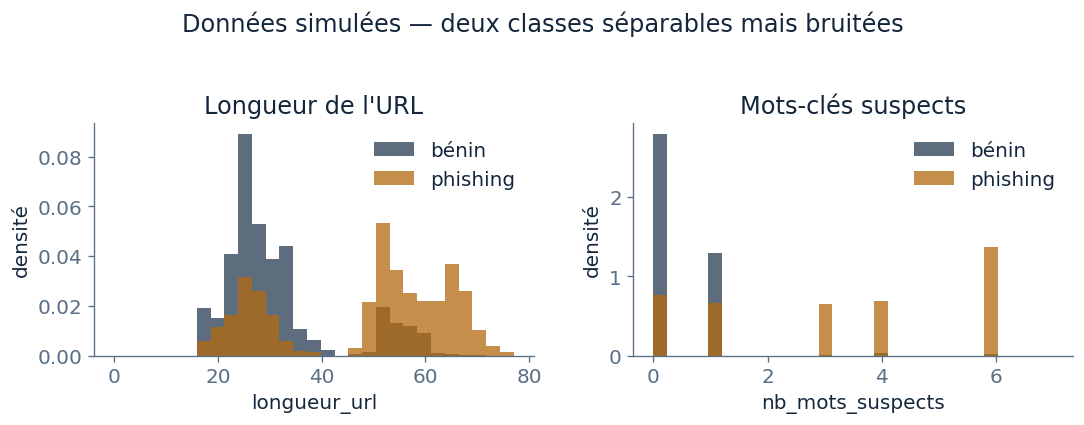

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.6))   # 1 ligne, 2 colonnes de figures
for ax, col, titre in [(axes[0], "longueur_url", "Longueur de l'URL"),
                       (axes[1], "nb_mots_suspects", "Mots-clés suspects")]:
    b = df[df.label == 0][col]      # valeurs chez les bénins
    p = df[df.label == 1][col]      # valeurs chez le phishing
    bins = np.linspace(0, max(b.max(), p.max()) + 1, 30)   # 30 intervalles communs
    ax.hist(b, bins=bins, color=BLEU, alpha=0.75, label="bénin", density=True)
    ax.hist(p, bins=bins, color=BRONZE, alpha=0.75, label="phishing", density=True)
    ax.set_title(titre); ax.set_xlabel(col); ax.set_ylabel("densité")
    ax.legend(frameon=False)
fig.suptitle("Données simulées — deux classes séparables mais bruitées", color=NAVY)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 5. Couper en entraînement / test — et éviter le surapprentissage

**Règle d'or : on n'évalue JAMAIS un modèle sur les données qui ont servi à
l'entraîner.** Sinon on triche : le modèle pourrait simplement *mémoriser* les
exemples (c'est le **surapprentissage**, *overfitting*) et sembler excellent, puis
échouer sur de vraies URLs nouvelles.

> **Analogie.** Réviser avec les annales **corrigées** (entraînement), puis passer un
> examen avec un sujet **jamais vu** (test). Si vous apprenez les corrigés par cœur
> sans comprendre la méthode, vous réussissez les annales mais ratez l'examen : c'est
> le surapprentissage.

On garde donc **25 % des URLs de côté** (le **jeu de test**), qu'on ne touchera qu'à
la toute fin pour mesurer. Les 75 % restants servent à **apprendre**.

Détail des arguments de `train_test_split` :
- `test_size=0.25` : 25 % pour le test.
- `random_state=GRAINE` : le mélange est **reproductible** (même graine ⟹ même coupe).
- `stratify=y` : on **conserve la même proportion** de phishing/bénin dans les deux
  moitiés (sinon le test pourrait, par hasard, contenir très peu de phishing).

In [11]:
# X = les caractéristiques (ce que le modèle VOIT). y = les étiquettes (la RÉPONSE).
X = df[FEATURES].values     # tableau numpy : 2000 lignes x 11 colonnes
y = df["label"].values      # tableau numpy : 2000 étiquettes (0 ou 1)

# On découpe des INDICES (0..1999) pour pouvoir retrouver les URLs plus tard.
itr, ite = train_test_split(
    np.arange(len(df)),     # tous les indices
    test_size=0.25,         # 25 % pour le test
    random_state=GRAINE,    # mélange reproductible
    stratify=y)             # même proportion de classes des deux côtés
Xtr, Xte = X[itr], X[ite]   # caractéristiques : entraînement / test
ytr, yte = y[itr], y[ite]   # étiquettes : entraînement / test
print(f"entraînement : {len(Xtr)} URLs   test : {len(Xte)} URLs")
print(f"part de phishing en test : {yte.mean()*100:.1f} %")

entraînement : 1500 URLs   test : 500 URLs
part de phishing en test : 29.0 %


## 6. Entraîner deux modèles

### Modèle 1 — la régression logistique (un classifieur, on l'a dit !)

Elle apprend une **frontière linéaire** : une somme pondérée des caractéristiques
$w_1 x_1 + w_2 x_2 + \dots + b$, transformée en **probabilité** par la sigmoïde.
« Entraîner » = trouver les poids $w$ et le biais $b$ qui séparent au mieux les deux
classes sur le jeu d'entraînement.

Deux outils autour d'elle :
- **`StandardScaler`** (*standardisation*) : ramène chaque caractéristique à une
  **moyenne de 0 et un écart-type de 1**. Pourquoi ? Sans ça, une caractéristique
  exprimée en grandes valeurs (ex. `longueur_url` ~ 40) écraserait une petite
  (ex. `est_ip` ~ 0 ou 1) **à cause de son unité**, pas de son importance. On met
  tout à la même échelle.
- **`make_pipeline`** : enchaîne `StandardScaler` **puis** `LogisticRegression` en un
  seul objet. Avantage : le scaler est ajusté **uniquement sur l'entraînement**, puis
  appliqué au test — pas de fuite d'information.
- `max_iter=1000` : nombre maximal d'itérations de l'optimisation (assez pour
  converger ici).

### Modèle 2 — la forêt aléatoire (*random forest*)

**Qu'est-ce qu'un arbre de décision ?** Un enchaînement de questions oui/non sur les
caractéristiques, comme un jeu de « 20 questions » :

> « `nb_mots_suspects` ≥ 2 ? » → oui → « `est_ip` = 1 ? » → oui → **phishing** ; sinon → …

Un **arbre seul** a tendance à **surapprendre** (il mémorise les exemples). La
**forêt aléatoire** corrige ça avec deux idées :

1. **Beaucoup d'arbres** (`n_estimators=200`) : on en construit 200, pas un seul.
2. **Du hasard dans chaque arbre** (le mot « aléatoire ») : chaque arbre est entraîné
   sur un **échantillon aléatoire des lignes** et ne considère qu'un **sous-ensemble
   aléatoire des caractéristiques** à chaque question. Les arbres sont donc
   **différents** les uns des autres.

Pour prédire, **chaque arbre vote** et la **majorité** l'emporte.

> **Analogie.** Plutôt que de faire confiance à **un** expert (qui peut se tromper ou
> être biaisé), on interroge **200 experts légèrement différents** et on prend la
> **majorité**. La foule diverse est plus fiable qu'un individu seul. C'est le
> principe des **méthodes d'ensemble** (*ensemble learning*).

`random_state=GRAINE` fixe le hasard des échantillons et des caractéristiques : la
forêt est **reproductible**. Bonus : une forêt sait dire **quelles caractéristiques
ont le plus compté** (`feature_importances_`, section 9).

In [12]:
# MODÈLE 1 : régression logistique, précédée d'une standardisation.
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(Xtr, ytr)    # .fit = ENTRAÎNER : le modèle apprend sur (caractéristiques, étiquettes)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [13]:
# MODÈLE 2 : forêt aléatoire de 200 arbres, hasard fixé par la graine.
rf = RandomForestClassifier(n_estimators=200, random_state=GRAINE)
rf.fit(Xtr, ytr)    # entraînement

RandomForestClassifier(n_estimators=200, random_state=42)

### Mesurer l'exactitude — et son piège

`.score(Xte, yte)` rend l'**exactitude** (*accuracy*) : la **part de bonnes
réponses** sur le jeu de **test**.

**Piège classique :** avec des classes **déséquilibrées** (ici ~29 % de phishing),
un modèle stupide qui répond **toujours « bénin »** obtient déjà ~71 % d'exactitude !
L'exactitude seule ne suffit donc pas : il faut la comparer à cette **référence
naïve**, et regarder la matrice de confusion (section 7).

In [14]:
acc_lr = lr.score(Xte, yte)     # exactitude de la régression logistique sur le test
acc_rf = rf.score(Xte, yte)     # exactitude de la forêt aléatoire sur le test
print(f"Régression logistique — exactitude test : {acc_lr*100:.1f} %")
print(f"Random Forest         — exactitude test : {acc_rf*100:.1f} %")
# Référence naïve : tout prédire « bénin ».
print(f"Référence (tout prédire bénin) : {(yte==0).mean()*100:.1f} %")

Régression logistique — exactitude test : 89.8 %
Random Forest         — exactitude test : 90.0 %
Référence (tout prédire bénin) : 71.0 %


## 7. La matrice de confusion — lire les erreurs en détail

L'exactitude cache **quelles** erreurs on fait. La **matrice de confusion** est un
tableau 2×2 qui croise la **vérité** (lignes) et la **prédiction** (colonnes) :

| | prédit bénin | prédit phishing |
|---|---|---|
| **vrai bénin** | Vrai Négatif (VN) | **Faux Positif (FP)** |
| **vrai phishing** | **Faux Négatif (FN)** | Vrai Positif (VP) |

En cybersécurité, les deux erreurs n'ont **pas du tout** le même coût :
- **Faux positif (FP)** : on bloque un site **légitime** → gêne pour l'utilisateur,
  mais pas de brèche.
- **Faux négatif (FN)** : on laisse passer un **phishing** → risque de **vol
  d'identifiants**, c'est grave.

Trois mesures résument la matrice (pour la classe « phishing ») :
- **Précision** = VP / (VP + FP) : *parmi tout ce qu'on a signalé comme phishing,
  quelle part l'était vraiment ?* (éviter les fausses alertes)
- **Rappel** (*recall*) = VP / (VP + FN) : *parmi tout le phishing réel, quelle part
  a-t-on attrapée ?* (ne rien laisser passer)
- **F1** = moyenne harmonique de précision et rappel : un compromis entre les deux.

> Précision et rappel **tirent dans des sens opposés** : signaler large augmente le
> rappel mais baisse la précision. C'est tout l'enjeu du **seuil** (section 8).

In [15]:
pred_rf = rf.predict(Xte)               # classe prédite (0/1) pour chaque URL de test
cm = confusion_matrix(yte, pred_rf)     # tableau 2x2 : vérité (lignes) x prédiction (colonnes)
print("                prédit bénin   prédit phishing")
print(f"vrai bénin      {cm[0,0]:10d}   {cm[0,1]:13d}")   # VN | FP
print(f"vrai phishing   {cm[1,0]:10d}   {cm[1,1]:13d}")   # FN | VP
print()
# Rapport complet : précision, rappel, F1 pour chaque classe + moyennes.
print(classification_report(yte, pred_rf, target_names=["bénin", "phishing"], digits=3))

                prédit bénin   prédit phishing
vrai bénin             337              18
vrai phishing           32             113

              precision    recall  f1-score   support

       bénin      0.913     0.949     0.931       355
    phishing      0.863     0.779     0.819       145

    accuracy                          0.900       500
   macro avg      0.888     0.864     0.875       500
weighted avg      0.899     0.900     0.898       500



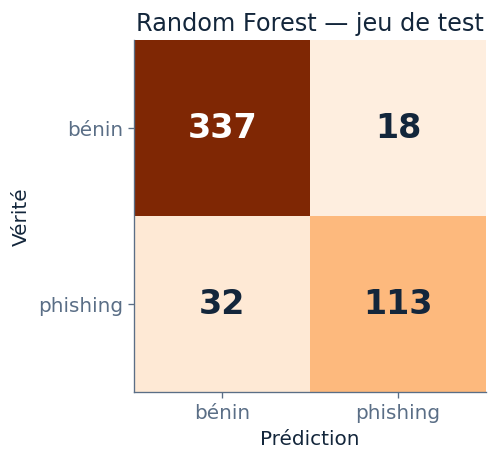

In [16]:
# La même matrice, en image (plus lisible).
fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.imshow(cm, cmap="Oranges", vmin=0, vmax=cm.max())   # cases colorées selon l'effectif
classes = ["bénin", "phishing"]
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(classes); ax.set_yticklabels(classes)
ax.set_xlabel("Prédiction"); ax.set_ylabel("Vérité")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max()*0.55 else NAVY,
                fontsize=20, fontweight="bold")
ax.set_title("Random Forest — jeu de test")
fig.tight_layout(); plt.show()

## 8. Le seuil de décision change tout

La régression logistique ne sort pas directement une classe : elle sort une
**probabilité** de phishing (entre 0 et 1). On choisit ensuite un **seuil** :
« si probabilité ≥ seuil, alors phishing ». Par défaut, seuil = 0,5.

**Mais 0,5 n'est pas sacré.** En cybersécurité, on préfère souvent **attraper un
maximum de phishing** (rappel élevé), quitte à bloquer quelques sites légitimes
(précision plus basse). On **abaisse** alors le seuil. À l'inverse, pour éviter les
fausses alertes, on le **monte**.

On balaie 91 seuils de 0,05 à 0,95 et on trace précision / rappel / F1 pour chacun.

In [17]:
proba = lr.predict_proba(Xte)[:, 1]    # probabilité de phishing pour chaque URL de test
seuils = np.linspace(0.05, 0.95, 91)   # 91 seuils testés
prec, rap, f1 = [], [], []
for s in seuils:
    # (proba >= s) : True/False ; .astype(int) : 1/0 ; on compare à la vérité yte.
    p, r, f, _ = precision_recall_fscore_support(
        yte, (proba >= s).astype(int), average="binary", zero_division=0)
    prec.append(p); rap.append(r); f1.append(f)
prec, rap, f1 = np.array(prec), np.array(rap), np.array(f1)
best = seuils[int(np.argmax(f1))]      # le seuil qui maximise le F1

In [18]:
i05 = int(np.argmin(abs(seuils - 0.5)))   # l'indice du seuil le plus proche de 0,50
print(f"seuil par défaut 0,50 : précision {prec[i05]:.3f}  rappel {rap[i05]:.3f}")
print(f"seuil F1 maximal {best:.2f} : F1 = {f1.max():.3f}")
i90 = int(np.argmin(abs(rap - 0.90)))     # le seuil qui donne ~90 % de rappel
print(f"pour un rappel de 90 % : seuil {seuils[i90]:.2f}, précision {prec[i90]:.3f}")

seuil par défaut 0,50 : précision 0.952  rappel 0.683
seuil F1 maximal 0.25 : F1 = 0.818
pour un rappel de 90 % : seuil 0.12, précision 0.439


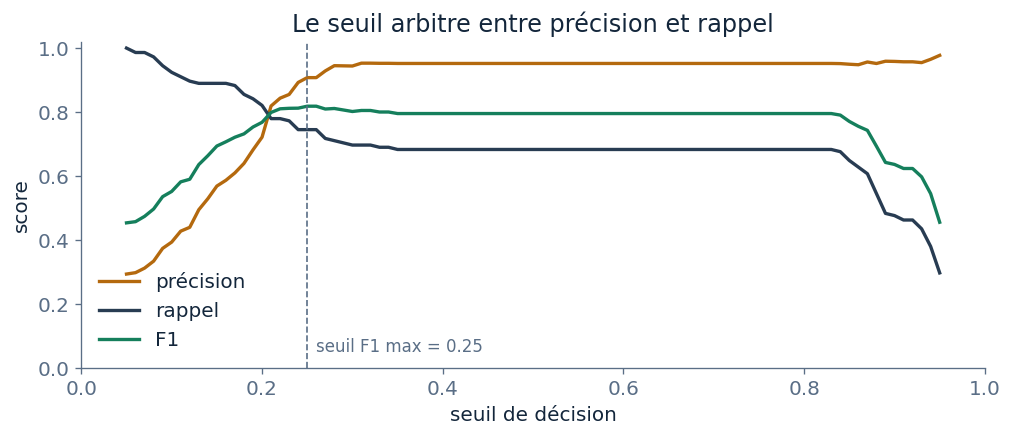

In [19]:
fig, ax = plt.subplots(figsize=(8.6, 3.8))
ax.plot(seuils, prec, color=BRONZE, lw=2, label="précision")
ax.plot(seuils, rap, color=BLEU, lw=2, label="rappel")
ax.plot(seuils, f1, color=VERT, lw=2, label="F1")
ax.axvline(best, color=GRIS, ls="--", lw=1)
ax.text(best + 0.01, 0.05, f"seuil F1 max = {best:.2f}", color=GRIS, fontsize=10)
ax.set_xlabel("seuil de décision"); ax.set_ylabel("score")
ax.set_ylim(0, 1.02); ax.set_xlim(0, 1)
ax.set_title("Le seuil arbitre entre précision et rappel")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); plt.show()

### La courbe ROC et l'AUC

La **courbe ROC** trace le **taux de vrais positifs** (le rappel) en fonction du
**taux de faux positifs**, quand on fait varier le seuil. Plus elle est « collée » au
coin haut-gauche, meilleur est le modèle.

L'**AUC** (*Area Under the Curve*) = l'**aire sous cette courbe**, entre 0 et 1 :
- **1,0** = modèle parfait ;
- **0,5** = modèle qui ne vaut pas mieux que le hasard (la diagonale).

C'est une mesure **indépendante du seuil** : elle résume la capacité du modèle à
*classer* les URLs (mettre les phishing devant les bénins), quel que soit le seuil
choisi ensuite.

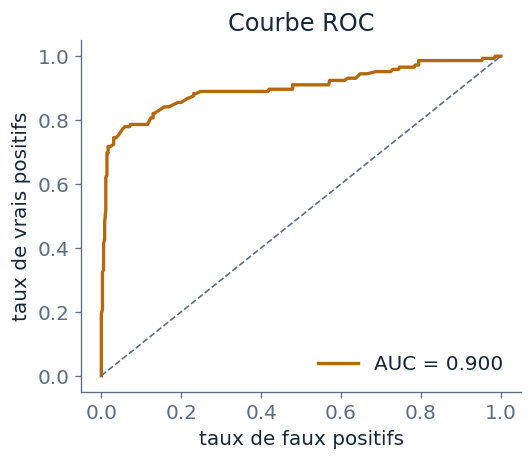

In [20]:
fpr, tpr, _ = roc_curve(yte, proba)   # taux de faux positifs / vrais positifs par seuil
aire = auc(fpr, tpr)                  # aire sous la courbe ROC
fig, ax = plt.subplots(figsize=(4.6, 4.0))
ax.plot(fpr, tpr, color=BRONZE, lw=2, label=f"AUC = {aire:.3f}")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)   # diagonale = hasard (AUC 0,5)
ax.set_xlabel("taux de faux positifs"); ax.set_ylabel("taux de vrais positifs")
ax.set_title("Courbe ROC")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

## 9. Quelles caractéristiques comptent ?

La forêt aléatoire fournit `feature_importances_` : un nombre par caractéristique,
**d'autant plus grand qu'elle a servi à bien séparer les classes** (la somme vaut 1).
C'est un outil d'**explicabilité** : il aide à comprendre *pourquoi* le modèle décide,
et à vérifier qu'il s'appuie sur des signaux sensés (pas sur un artefact).

In [21]:
imp = rf.feature_importances_    # importance de chaque caractéristique (somme = 1)
# Les 6 plus importantes, triées par ordre décroissant :
for nom, v in sorted(zip(FEATURES, imp), key=lambda t: -t[1])[:6]:
    print(f"{nom:20s} {v:.3f}")

nb_mots_suspects     0.301
longueur_hote        0.234
longueur_url         0.176
nb_sous_domaines     0.064
nb_points            0.062
nb_tirets            0.052


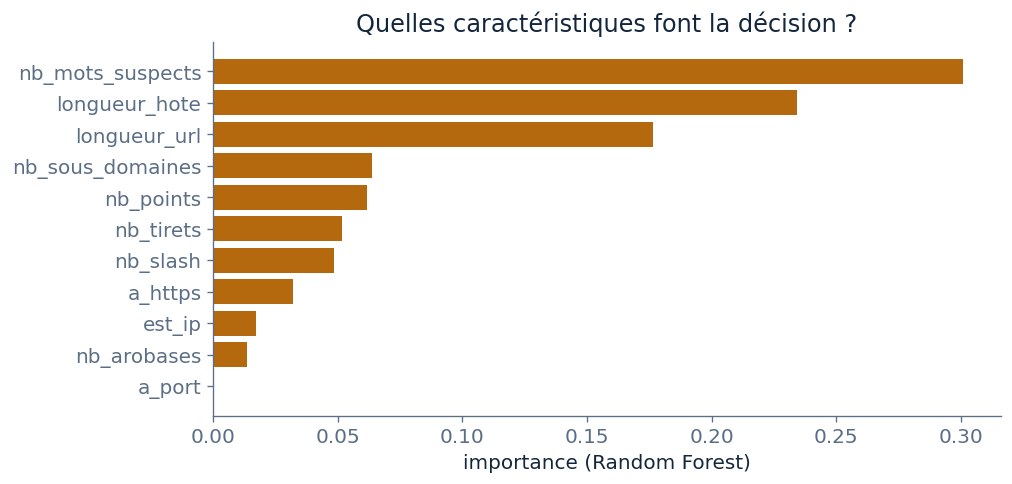

In [22]:
ordre = np.argsort(imp)          # indices qui trient les importances (croissant)
fig, ax = plt.subplots(figsize=(8.6, 4.2))
ax.barh(np.array(FEATURES)[ordre], imp[ordre], color=BRONZE)   # barres horizontales
ax.set_xlabel("importance (Random Forest)")
ax.set_title("Quelles caractéristiques font la décision ?")
fig.tight_layout(); plt.show()

## 10. Fragilité : réécrire l'URL suffit à tromper le modèle

Démonstration finale, essentielle en cybersécurité. On prend une URL de phishing
**bien détectée**, puis on la **réécrit** pour lui donner une apparence légitime
(même marque, HTTPS, court). Le modèle, qui ne juge que l'**apparence** (les
caractéristiques), se laisse avoir.

> **Leçon.** Un modèle de ML n'est **pas** une garantie de sécurité : il juge des
> *caractéristiques*, pas l'*intention*. Un attaquant qui connaît vos features peut
> les manipuler (attaque **adversariale** / *evasion*). La défense en profondeur
> (réputation de domaine, analyse du contenu, MFA…) reste indispensable.

In [23]:
# Une URL de phishing du test que le modèle a BIEN détectée (vraie=1, prédite=1).
idx = np.where((yte == 1) & (pred_rf == 1))[0][0]
url0 = df.iloc[ite[idx]]["url"]
x0 = np.array([caracteristiques(url0)[f] for f in FEATURES], dtype=float)
s0 = rf.predict_proba(x0.reshape(1, -1))[0, 1]    # score phishing de l'URL d'origine

# La même « marque », mais réécrite pour ressembler à un site légitime.
url1 = "https://www.netflix.com/"
x1 = np.array([caracteristiques(url1)[f] for f in FEATURES], dtype=float)
s1 = rf.predict_proba(x1.reshape(1, -1))[0, 1]    # score phishing de l'URL réécrite

print(f"URL d'origine (phishing) : {url0}")
print(f"  score phishing = {s0:.3f} -> détecté")
print(f"URL réécrite (apparence légitime) : {url1}")
print(f"  score phishing = {s1:.3f} -> "
      f"{'bénin' if rf.predict(x1.reshape(1,-1))[0]==0 else 'phishing'}")
print("Leçon : le modèle juge l'apparence (caractéristiques), pas l'intention.")

URL d'origine (phishing) : http://170.198.209.253/banking/confirm/netflix/confirm.php
  score phishing = 0.926 -> détecté
URL réécrite (apparence légitime) : https://www.netflix.com/
  score phishing = 0.156 -> bénin
Leçon : le modèle juge l'apparence (caractéristiques), pas l'intention.


## Récapitulatif

Vous avez construit, de bout en bout, un petit système de détection de phishing :

1. **Données simulées** étiquetées (2 000 URLs, graine fixée, ~7 % de bruit).
2. **11 caractéristiques** lexicales par URL (le modèle ne voit que des nombres).
3. **Coupe entraînement / test** (75 / 25, stratifiée, reproductible) pour éviter le
   surapprentissage.
4. **Deux modèles** : régression logistique (un classifieur probabiliste) et forêt
   aléatoire (200 arbres qui votent).
5. **Évaluation honnête** : exactitude comparée à la référence naïve, matrice de
   confusion, précision / rappel / F1.
6. **Le seuil** comme décision de sécurité (rappel élevé vs fausses alertes), ROC/AUC.
7. **Explicabilité** (importance des caractéristiques) et **fragilité** (une URL
   réécrite trompe le modèle).

### Glossaire express

- **Caractéristique (feature)** : un nombre décrivant un exemple.
- **Étiquette (label)** : la bonne réponse connue (0 bénin / 1 phishing).
- **Graine aléatoire (random_state)** : fixe le pseudo-hasard → résultats reproductibles.
- **Régression** : prédire un nombre continu. **Classification** : prédire une catégorie.
- **Régression logistique** : malgré son nom, un **classifieur** (score → sigmoïde → probabilité → seuil).
- **Forêt aléatoire** : ensemble de nombreux arbres diversifiés (hasard sur lignes +
  caractéristiques) qui **votent** ; plus robuste qu'un arbre seul.
- **Surapprentissage (overfitting)** : mémoriser l'entraînement au lieu de généraliser.
- **Standardisation (StandardScaler)** : mettre chaque caractéristique à moyenne 0, écart-type 1.
- **Exactitude (accuracy)** : part de bonnes réponses (piège si classes déséquilibrées).
- **Précision** : parmi les alertes, part de vraies. **Rappel** : parmi les vrais, part attrapée. **F1** : compromis.
- **Seuil** : probabilité limite pour décider « phishing ».
- **ROC / AUC** : courbe rappel vs fausses alertes ; aire = qualité de classement (1 parfait, 0,5 hasard).

### Pour aller plus loin (exercices)

1. Changez `GRAINE` (ex. 7) et relancez *Run All* : les chiffres bougent-ils ? Pourquoi ?
2. Passez `test_size` à 0,40 : l'exactitude change-t-elle ? Le modèle a-t-il moins appris ?
3. Retirez la caractéristique `nb_mots_suspects` de `FEATURES` : que perd la forêt ?
4. Ajoutez une caractéristique (ex. `nb_chiffres` = nombre de chiffres dans l'URL) :
   modifiez `caracteristiques`, `FEATURES`, relancez. L'importance évolue-t-elle ?
5. Abaissez le seuil à 0,20 : combien de phishing attrapés en plus, et combien de sites
   légitimes bloqués à tort ? Discutez le choix « sécurité vs confort ».
6. Entraînez un **arbre de décision seul** (`sklearn.tree.DecisionTreeClassifier`) et
   comparez son exactitude à la forêt : illustrez le surapprentissage.

---

*Données 100 % simulées, hors ligne, reproductibles (graine 42). Support pédagogique
du cours « Introduction à l'intelligence artificielle » — M2 Cybersécurité.*